# Práctica 2.4 · Un modelo ARIMA para pronosticar el precio de una canasta

Este cuaderno acompaña las clases «Series de tiempo: conceptos» y «Modelo ARIMA». Sigue los pasos de Box-Jenkins con una serie mensual:

1. La serie · 2. **Estacionariedad**: media y desviación móviles y prueba ADF · 3. ACF y PACF · 4. Partición en el tiempo · 5. **Elegir el orden con el AIC** · 6. **Revisar los residuos** · 7. **Pronóstico y métricas** contra dos líneas base · 8. Origen móvil · 9. El pronóstico hacia adelante

**Datos.** `datos/2-4-serie-arima.xlsx`: 240 meses (enero de 2005 a diciembre de 2024) de un índice del precio de una canasta básica, **simulado con fines didácticos** (enero de 2005 = 100).

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
import warnings; warnings.filterwarnings('ignore')

DATOS = Path('datos')   # en Colab, suba la carpeta datos/ al entorno
SEMILLA = 42
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')

In [2]:
# Estilo gráfico común (paleta validada para daltonismo)
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

AZUL, NARANJA, AQUA, ROJO = '#2a78d6', '#eb6834', '#1baf7a', '#e34948'
GRIS, TINTA, TINTA2 = '#898781', '#0b0b0b', '#52514e'
SEQ = LinearSegmentedColormap.from_list('azul', ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
DIV = LinearSegmentedColormap.from_list('div', ['#1c5cab', '#86b6ef', '#f0efec', '#ee9a99', '#b02e2e'])

mpl.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': TINTA2, 'text.color': TINTA,
    'xtick.color': GRIS, 'ytick.color': GRIS, 'axes.grid': True, 'grid.color': '#e1e0d9',
    'grid.linewidth': 0.6, 'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'figure.dpi': 110, 'lines.linewidth': 2, 'legend.frameon': False,
})

## 1. La serie

240 meses, de ene 2005 a dic 2024 · de 100.0 a 260.4 · faltantes: 0


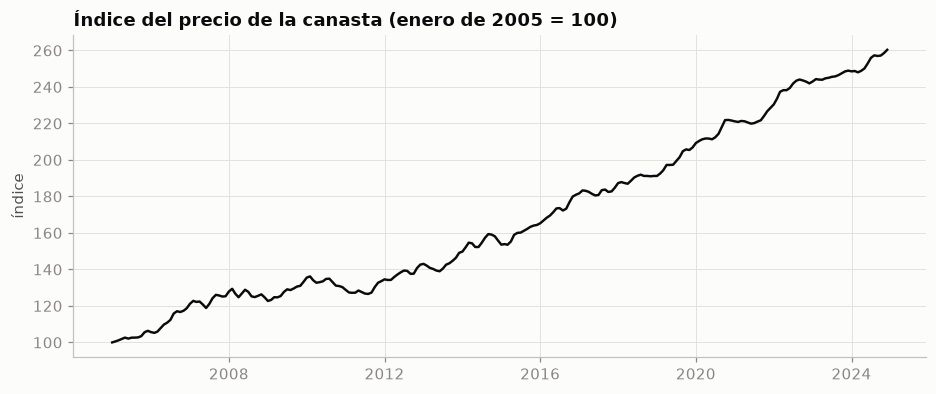

In [3]:
mes = lambda d: ['ene', 'feb', 'mar', 'abr', 'may', 'jun', 'jul', 'ago', 'sep', 'oct', 'nov', 'dic'][d.month - 1] + f' {d.year}'
ser = pd.read_excel(DATOS / '2-4-serie-arima.xlsx', sheet_name='serie', parse_dates=['fecha']).set_index('fecha')['precio_canasta'].asfreq('MS')
print(f'{len(ser)} meses, de {mes(ser.index[0])} a {mes(ser.index[-1])} · de {ser.iloc[0]:.1f} a {ser.iloc[-1]:.1f} · faltantes: {ser.isna().sum()}')
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(ser, color=TINTA, lw=1.6)
ax.set(title='Índice del precio de la canasta (enero de 2005 = 100)', ylabel='índice')
plt.show()

El índice pasa de 100,0 a 260,4 en 240 meses: subió un 160 %. Tiene una **tendencia** clara hacia arriba, con altibajos de corto plazo y sin una temporada que se repita cada año. No hay datos faltantes y el espaciamiento es regular (un dato por mes).

## 2. ¿Es estacionaria?

Una serie es **estacionaria** si su media y su desviación estándar no cambian con el tiempo. ARIMA la necesita así, y si no lo es, se **diferencia**: Δyₜ = yₜ − yₜ₋₁.

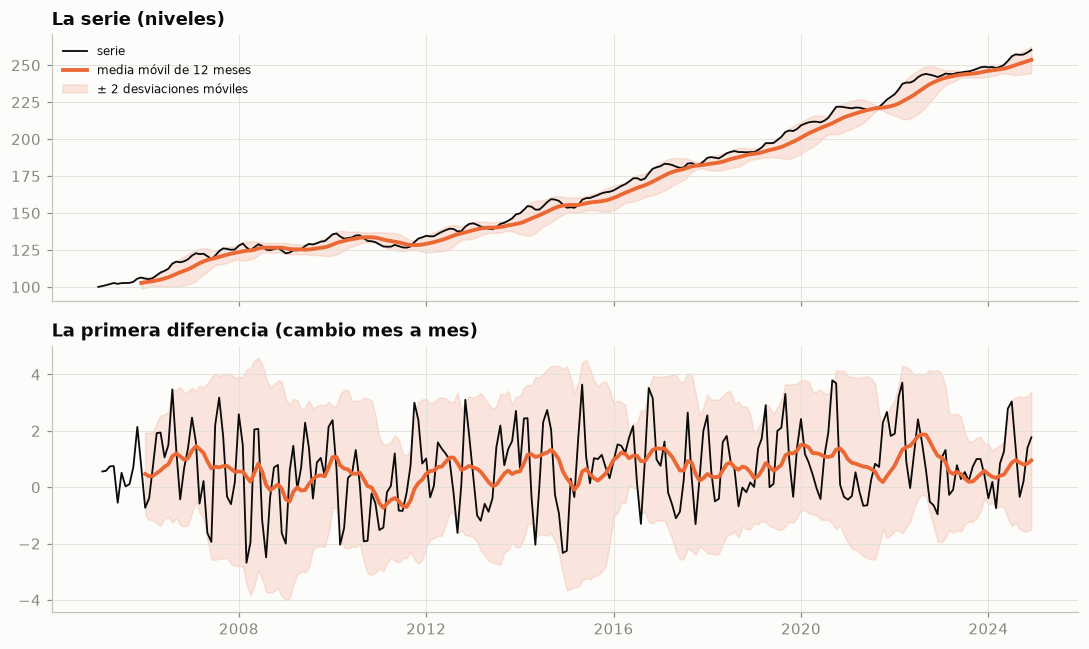

,estadístico ADF,valor p,rezagos usados
niveles,1.329,0.997,3.000
primera diferencia,-7.975,0.000,2.000


In [4]:
dif = ser.diff().dropna()
fig, axs = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for ax, s, nom in [(axs[0], ser, 'La serie (niveles)'), (axs[1], dif, 'La primera diferencia (cambio mes a mes)')]:
    m, d = s.rolling(12).mean(), s.rolling(12).std()
    ax.plot(s, color=TINTA, lw=1.2, label='serie')
    ax.plot(m, color=NARANJA, lw=2.5, label='media móvil de 12 meses')
    ax.fill_between(s.index, m - 2 * d, m + 2 * d, color=NARANJA, alpha=.15, label='± 2 desviaciones móviles')
    ax.set(title=nom)
axs[0].legend(fontsize=8, loc='upper left')
plt.tight_layout(); plt.show()

def adf(s):
    r = adfuller(s, autolag='AIC')
    return {'estadístico ADF': r[0], 'valor p': r[1], 'rezagos usados': r[2]}
tab_adf = pd.DataFrame({'niveles': adf(ser), 'primera diferencia': adf(dif)}).T
tab_adf

Arriba, la media móvil sube todo el tiempo: la serie **no es estacionaria**. Abajo, la diferencia mes a mes gira alrededor de una media constante (unos 0,67 puntos por mes) con una dispersión parecida en todo el período.

La **prueba de Dickey-Fuller aumentada (ADF)** lo confirma. Su hipótesis nula es que la serie no es estacionaria (tiene raíz unitaria). En niveles, el valor p es 0,997: no se rechaza. En la primera diferencia es 0,0000: se rechaza. **Una diferencia basta: d = 1.**

## 3. ACF y PACF de la serie diferenciada

La **ACF** (autocorrelación) mide cuánto se parece la serie a sí misma k meses antes. La **PACF** (autocorrelación parcial) mide lo mismo, pero después de quitar el efecto de los rezagos intermedios. Sirven de pista para el orden: en un AR(p) la PACF se corta después de p, y en un MA(q) la ACF se corta después de q.

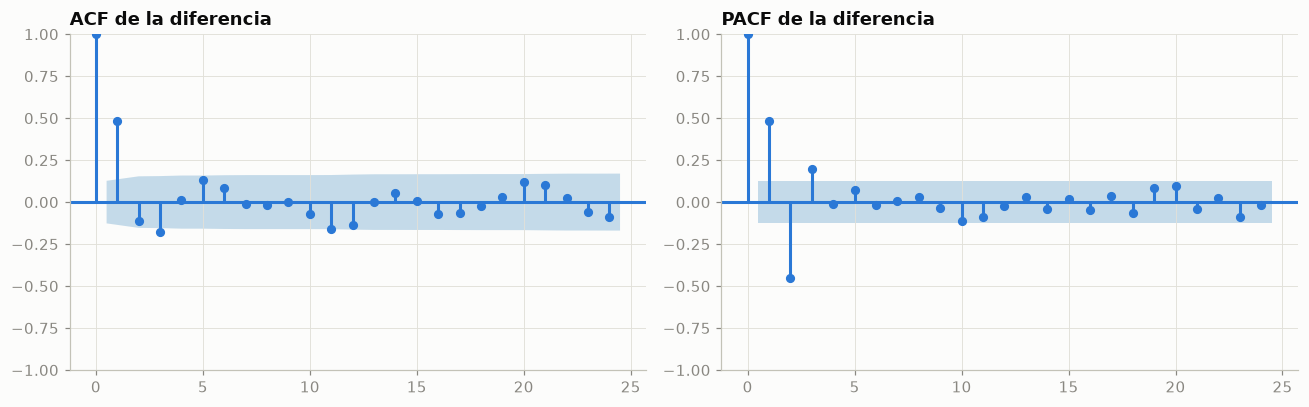

ACF  1-4: [ 0.48 -0.11 -0.18  0.01]
PACF 1-4: [ 0.48 -0.45  0.19 -0.01]
banda ±0.13


In [5]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
plot_acf(dif, lags=24, ax=axs[0], color=AZUL, vlines_kwargs={'colors': AZUL}, title='ACF de la diferencia')
plot_pacf(dif, lags=24, ax=axs[1], color=AZUL, vlines_kwargs={'colors': AZUL}, title='PACF de la diferencia', method='ywm')
plt.tight_layout(); plt.show()
from statsmodels.tsa.stattools import acf as _acf, pacf as _pacf
r_acf, r_pacf = _acf(dif, nlags=6), _pacf(dif, nlags=6, method='ywm')
print('ACF  1-4:', np.round(r_acf[1:5], 2)); print('PACF 1-4:', np.round(r_pacf[1:5], 2)); print(f'banda ±{1.96 / np.sqrt(len(dif)):.2f}')

La ACF tiene una barra alta en el rezago 1 (0,48) y luego barras negativas más pequeñas (−0,11 y −0,18). La PACF tiene barras claras en los rezagos 1 (0,48) y 2 (−0,45), y una menor en el 3 (0,19). El patrón no es puro, así que lo más probable es una mezcla de AR y MA. Las gráficas dan candidatos, no la respuesta; para decidir se usa el AIC.

## 4. Partición en el tiempo

Los últimos 24 meses se apartan para la prueba. **Nunca al azar**: el modelo solo puede usar el pasado para pronosticar el futuro.

In [6]:
H = 24
tr, te = ser.iloc[:-H], ser.iloc[-H:]
print(f'entrenamiento: {mes(tr.index[0])} a {mes(tr.index[-1])} ({len(tr)} meses) · prueba: {mes(te.index[0])} a {mes(te.index[-1])} ({len(te)} meses)')

entrenamiento: ene 2005 a dic 2022 (216 meses) · prueba: ene 2023 a dic 2024 (24 meses)


El modelo se estima con 216 meses y se evalúa con los 24 siguientes.

## 5. Elegir el orden con el AIC

Se ajustan todos los ARIMA(p, 1, q) con p y q de 0 a 3, con **deriva** (una constante en la diferencia: lo que sube la serie en promedio cada mes). El **AIC** (criterio de información de Akaike) premia el buen ajuste y castiga cada parámetro de más. Gana el menor.

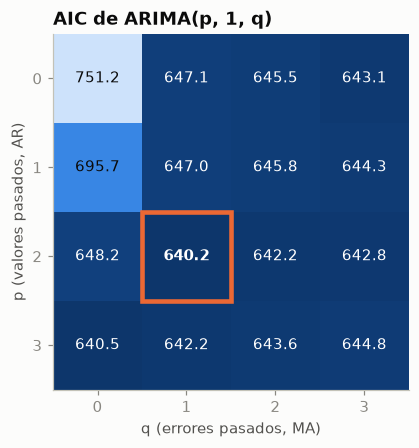

Menor AIC: ARIMA(2, 1, 1)


,p,q,AIC,BIC
9,2,1,640.249,657.102
12,3,0,640.518,657.372
13,3,1,642.174,662.398
10,2,2,642.223,662.447
11,2,3,642.762,666.356


In [7]:
filas = []
for p in range(4):
    for q in range(4):
        try:
            f = ARIMA(tr, order=(p, 1, q), trend='t').fit()
            filas.append({'p': p, 'q': q, 'AIC': f.aic, 'BIC': f.bic})
        except Exception:
            pass
rej = pd.DataFrame(filas)
tabla = rej.pivot(index='p', columns='q', values='AIC')
P, Q = rej.loc[rej.AIC.idxmin(), ['p', 'q']].astype(int)
fig, ax = plt.subplots(figsize=(5.5, 4.2))
im = ax.imshow(tabla.values, cmap=SEQ.reversed())
for i in range(4):
    for j in range(4):
        ax.text(j, i, f'{tabla.values[i, j]:.1f}', ha='center', va='center', fontsize=10, color=TINTA if tabla.values[i, j] > tabla.values.min() + 8 else 'white',
                fontweight='bold' if (i, j) == (P, Q) else 'normal')
ax.add_patch(plt.Rectangle((Q - .5, P - .5), 1, 1, fill=False, ec=NARANJA, lw=3))
ax.set(xticks=range(4), yticks=range(4), xlabel='q (errores pasados, MA)', ylabel='p (valores pasados, AR)', title='AIC de ARIMA(p, 1, q)'); ax.grid(False)
plt.show()
print(f'Menor AIC: ARIMA({P}, 1, {Q})')
rej.sort_values('AIC').head(5)

El menor AIC es el de **ARIMA(2, 1, 1)**: 640,2 (recuadro naranja). Le siguen ARIMA(3, 1, 0) con 640,5 y ARIMA(3, 1, 1) con 642,2. Las diferencias de una o dos unidades de AIC son pequeñas: varios modelos describen la serie casi igual de bien, y conviene preferir el más simple entre los que están cerca.

In [8]:
mod = ARIMA(tr, order=(P, 1, Q), trend='t').fit()
coef = pd.DataFrame({'coeficiente': mod.params, 'error estándar': mod.bse, 'valor p': mod.pvalues})
coef.index = coef.index.map({'x1': 'deriva', 'ar.L1': 'φ₁ (AR 1)', 'ar.L2': 'φ₂ (AR 2)', 'ar.L3': 'φ₃ (AR 3)', 'ma.L1': 'θ₁ (MA 1)',
                             'ma.L2': 'θ₂ (MA 2)', 'ma.L3': 'θ₃ (MA 3)', 'sigma2': 'varianza del error'}.get)
coef

,coeficiente,error estándar,valor p
deriva,0.658,0.112,0.000
φ₁ (AR 1),0.380,0.132,0.004
φ₂ (AR 2),-0.297,0.099,0.003
θ₁ (MA 1),0.431,0.124,0.001
varianza del error,1.094,0.109,0.000


Los coeficientes estimados son: deriva = 0,658; φ₁ (AR 1) = 0,380; φ₂ (AR 2) = −0,297; θ₁ (MA 1) = 0,431; varianza del error = 1,094. Todos tienen un valor p menor que 0,05: son distintos de cero. La **deriva** de 0,658 es lo que el índice sube en promedio cada mes. Los φ dicen cuánto pesan los cambios de los meses anteriores en el de este mes, y el θ, cuánto pesa el error (la sorpresa) del mes pasado.

## 6. Revisar los residuos

Si el modelo capturó la estructura de la serie, lo que sobra (los **residuos**) debe parecer ruido: media cero, sin autocorrelación y sin patrones.

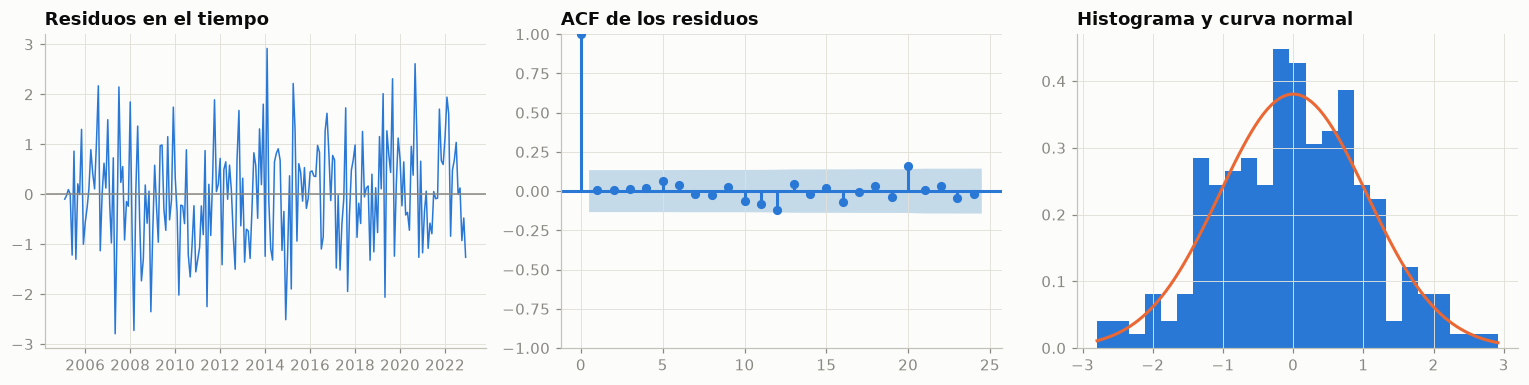

media de los residuos: 0.000 · desviación: 1.048


,lb_stat,lb_pvalue
6,1.459,0.962
12,7.719,0.807
24,17.409,0.831


In [9]:
res = mod.resid.iloc[1:]
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
axs[0].plot(res, color=AZUL, lw=1); axs[0].axhline(0, color=GRIS, lw=1); axs[0].set(title='Residuos en el tiempo')
plot_acf(res, lags=24, ax=axs[1], color=AZUL, vlines_kwargs={'colors': AZUL}, title='ACF de los residuos')
axs[2].hist(res, bins=25, color=AZUL, density=True)
xs = np.linspace(res.min(), res.max(), 100); axs[2].plot(xs, np.exp(-(xs - res.mean()) ** 2 / (2 * res.var())) / np.sqrt(2 * np.pi * res.var()), color=NARANJA)
axs[2].set(title='Histograma y curva normal')
plt.tight_layout(); plt.show()
lb = acorr_ljungbox(res, lags=[6, 12, 24])
print(f'media de los residuos: {res.mean():.3f} · desviación: {res.std():.3f}')
lb

Los residuos tienen media 0,000 y desviación 1,048, no muestran tendencia ni cambios de dispersión, y su histograma se parece a una normal. Ninguna barra de su ACF sale de la banda de forma clara. La prueba de **Ljung-Box** (hipótesis nula: no hay autocorrelación) da valores p de 0,96, 0,81 y 0,83 con 6, 12 y 24 rezagos: todos mayores que 0,05, así que no hay evidencia de estructura sin capturar. **El modelo pasa la revisión.**

## 7. Pronóstico de 24 meses y métricas

Desde diciembre de 2022 se pronostican los 24 meses de prueba de una sola vez, con su intervalo de 95 %, y se comparan con dos líneas base:
- **ingenuo**: todos los meses iguales al último valor conocido;
- **ingenuo con deriva**: el último valor más la subida promedio del entrenamiento, mes a mes.

Las métricas:
- **MAE** (error absoluto medio): en cuántos puntos del índice se equivoca, en promedio;
- **RMSE** (raíz del error cuadrático medio): castiga más los errores grandes;
- **MAPE** (error porcentual absoluto medio): el error relativo, en %.

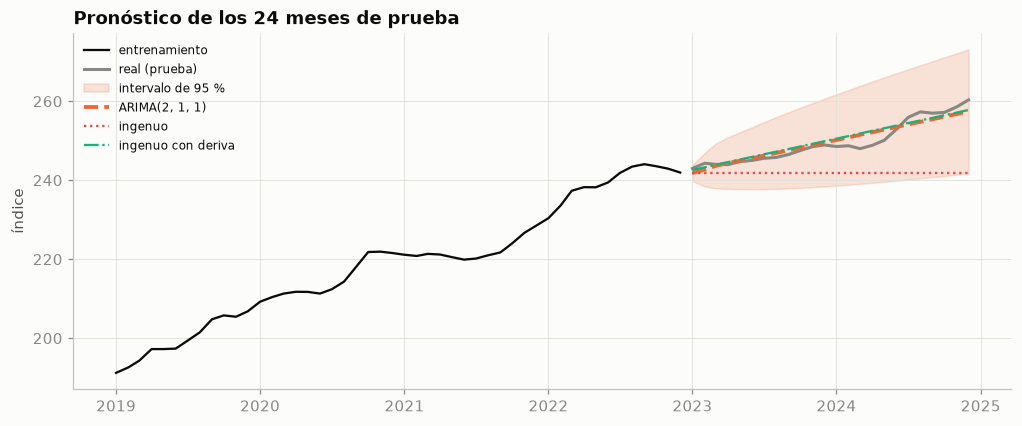

24 de 24 meses reales caen dentro del intervalo de 95 %


,MAE,RMSE,MAPE (%)
"ARIMA(2, 1, 1)",1.433,1.726,0.571
Ingenuo,7.691,9.287,3.039
Ingenuo con deriva,1.482,1.780,0.592


In [10]:
fc = mod.get_forecast(H)
pm, ic = fc.predicted_mean, fc.conf_int(alpha=0.05)
ing = pd.Series(tr.iloc[-1], index=te.index)
der = pd.Series(tr.iloc[-1] + tr.diff().mean() * np.arange(1, H + 1), index=te.index)
def met(real, pred):
    e = real - pred
    return {'MAE': e.abs().mean(), 'RMSE': (e ** 2).mean() ** 0.5, 'MAPE (%)': (e.abs() / real).mean() * 100}
tab = pd.DataFrame({f'ARIMA({P}, 1, {Q})': met(te, pm), 'Ingenuo': met(te, ing), 'Ingenuo con deriva': met(te, der)}).T
dentro = ((te >= ic.iloc[:, 0]) & (te <= ic.iloc[:, 1])).sum()

fig, ax = plt.subplots(figsize=(11, 4.2))
ver = ser.iloc[-72:]
ax.plot(ver.loc[:tr.index[-1]], color=TINTA, lw=1.5, label='entrenamiento')
ax.plot(te, color=GRIS, lw=2, label='real (prueba)')
ax.fill_between(ic.index, ic.iloc[:, 0], ic.iloc[:, 1], color=NARANJA, alpha=.18, label='intervalo de 95 %')
ax.plot(pm, color=NARANJA, lw=2.5, ls='--', label=f'ARIMA({P}, 1, {Q})')
ax.plot(ing, color=ROJO, lw=1.5, ls=':', label='ingenuo')
ax.plot(der, color=AQUA, lw=1.5, ls='-.', label='ingenuo con deriva')
ax.set(title='Pronóstico de los 24 meses de prueba', ylabel='índice'); ax.legend(fontsize=8, loc='upper left')
plt.show()
print(f'{dentro} de {H} meses reales caen dentro del intervalo de 95 %')
tab

En los 24 meses de prueba:

- El **ARIMA(2, 1, 1)** se equivoca en 1,43 puntos en promedio (MAPE 0,57 %).
- El **ingenuo**, que congela el último valor, se equivoca en 7,69 (MAPE 3,04 %): no ve que la serie sigue subiendo.
- El **ingenuo con deriva** se equivoca en 1,48 (MAPE 0,59 %). Es una línea base más exigente, porque ya incluye la tendencia.

24 de los 24 valores reales caen dentro del intervalo de 95 %, que se abre a medida que el pronóstico se aleja. **El ARIMA les gana a las dos líneas base.** A 24 meses, casi todo lo que aporta el modelo es la deriva: los términos AR y MA pesan sobre todo en los primeros meses del pronóstico, y eso es lo que mide la sección siguiente.

## 8. Origen móvil: pronóstico a un paso

En la práctica, cada mes llega un dato nuevo y se pronostica solo el siguiente. Se mantienen los coeficientes estimados con el entrenamiento y se van incorporando los datos reales de la prueba a medida que ocurren.

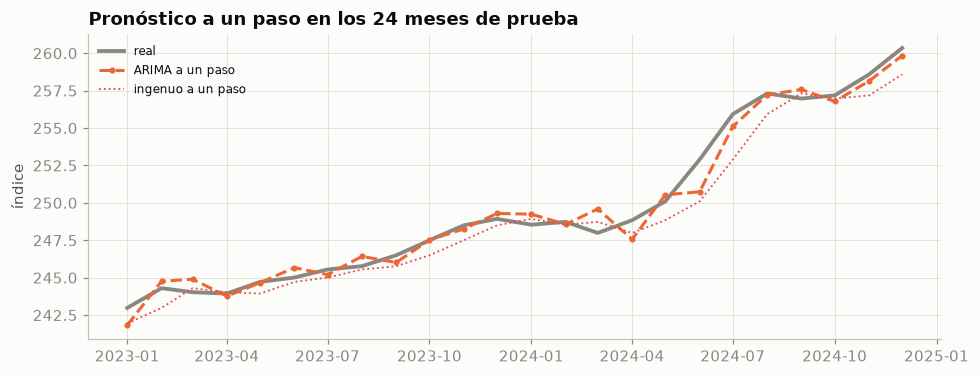

,MAE,RMSE,MAPE (%)
"ARIMA(2, 1, 1)",0.612,0.788,0.245
Ingenuo,0.920,1.188,0.366
Ingenuo con deriva,0.708,0.914,0.282


In [11]:
mod_todo = mod.apply(ser)                        # mismos coeficientes, toda la serie
paso = mod_todo.get_prediction(start=te.index[0]).predicted_mean
ing1 = ser.shift(1).loc[te.index]                 # el mes siguiente igual a este
der1 = ing1 + tr.diff().mean()                    # más la subida promedio
tab1 = pd.DataFrame({f'ARIMA({P}, 1, {Q})': met(te, paso), 'Ingenuo': met(te, ing1), 'Ingenuo con deriva': met(te, der1)}).T
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(te, color=GRIS, lw=2.5, label='real')
ax.plot(paso, color=NARANJA, lw=2, ls='--', marker='o', ms=3, label=f'ARIMA a un paso')
ax.plot(ing1, color=ROJO, lw=1.2, ls=':', label='ingenuo a un paso')
ax.set(title='Pronóstico a un paso en los 24 meses de prueba', ylabel='índice'); ax.legend(fontsize=8)
plt.show()
tab1

A un paso, el ARIMA se equivoca en 0,612 puntos en promedio (MAPE 0,245 %), frente a 0,920 del ingenuo y 0,708 del ingenuo con deriva. Aquí sí se ve el aporte de los términos AR y MA: usan los cambios y las sorpresas recientes para corregir el pronóstico del mes siguiente, algo que la deriva sola no hace.

## 9. El pronóstico hacia adelante

Para pronosticar de verdad se vuelve a estimar el modelo con **toda** la serie y se miran los 12 meses siguientes.

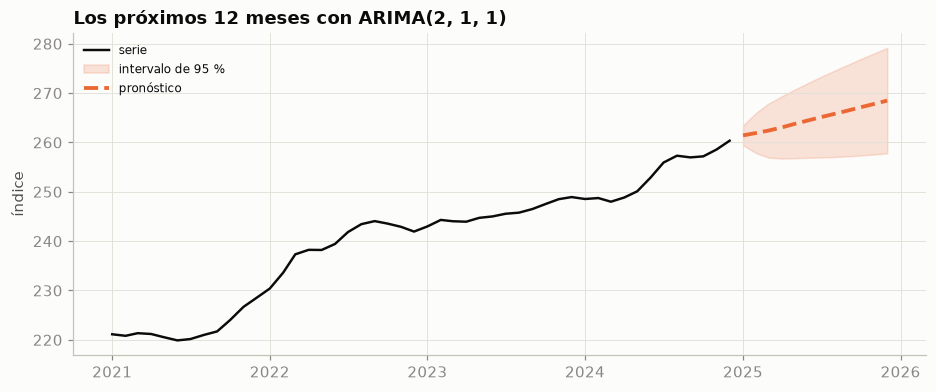

,pronóstico,mínimo 95 %,máximo 95 %
2025-01-01,261.429,259.425,263.433
2025-06-01,264.466,256.889,272.043
2025-12-01,268.479,257.783,279.174


In [12]:
fin = ARIMA(ser, order=(P, 1, Q), trend='t').fit()
f12 = fin.get_forecast(12); m12, i12 = f12.predicted_mean, f12.conf_int(alpha=0.05)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(ser.iloc[-48:], color=TINTA, lw=1.6, label='serie')
ax.fill_between(i12.index, i12.iloc[:, 0], i12.iloc[:, 1], color=NARANJA, alpha=.18, label='intervalo de 95 %')
ax.plot(m12, color=NARANJA, lw=2.5, ls='--', label='pronóstico')
ax.set(title=f'Los próximos 12 meses con ARIMA({P}, 1, {Q})', ylabel='índice'); ax.legend(fontsize=8, loc='upper left')
plt.show()
pd.DataFrame({'pronóstico': m12, 'mínimo 95 %': i12.iloc[:, 0], 'máximo 95 %': i12.iloc[:, 1]}).iloc[[0, 5, 11]]

El modelo pronostica que el índice pasará de 260,4 (diciembre de 2024) a 268,5 en diciembre de 2025, con un intervalo de 95 % entre 257,8 y 279,2. El intervalo se abre con el horizonte: a un mes, la incertidumbre es de ± 2,0 puntos; a doce, de ± 10,7.

## Conclusiones

1. La serie **no es estacionaria** en niveles (ADF: p = 0,997) y sí lo es en su primera diferencia (p = 0,0000): d = 1.
2. La ACF y la PACF dan pistas, pero el orden se eligió con el AIC: **ARIMA(2, 1, 1) con deriva**.
3. Los residuos parecen ruido (media ≈ 0; Ljung-Box sin autocorrelación): el modelo capturó la estructura.
4. En el pronóstico de 24 meses, el ARIMA (MAE 1,43) supera al ingenuo (MAE 7,69). Frente al ingenuo con deriva (MAE 1,48) la diferencia es menor: a largo plazo, lo que más pesa es la tendencia.
5. A un paso, el ARIMA (MAE 0,612) aprovecha los cambios y las sorpresas recientes y mejora a las dos líneas base (ingenuo: 0,920; con deriva: 0,708).
6. La partición siempre es en el tiempo y la comparación, siempre contra una línea base. Con la TRM real (clase de ARIMA y ejercicio 03), el ARIMA no logra ganarle al ingenuo; con esta serie, sí.

## Retos

1. Ajuste el ARIMA sin deriva (`trend='n'`). ¿Qué pasa con el pronóstico de 24 meses?
2. Elija el orden con el BIC en lugar del AIC (la columna ya está calculada). ¿Coinciden?
3. Use `pmdarima.auto_arima` (si lo tiene instalado) y compare el orden que elige.
4. Haga la validación con origen móvil **reestimando** el modelo cada mes. ¿Cambian mucho los coeficientes?
5. Pronostique a 6 meses en lugar de 24 y compare el MAE contra el ingenuo con deriva.
6. Aplique el mismo procedimiento a la TRM mensual (`datos/ej3_trm_mensual.csv`) y compare los resultados.